# Autotuning in Julia

_Part of this notebook is inspired by the material of the [Kernel Tuner tutorials](https://github.com/KernelTuner/kernel_tuner_tutorial)._

## Setup

Just some housekeeping before we begin.
Start by running the command in the README if you haven't done so yet. 
Then run the cell below. 

In [1]:
# Activate environment and install the packages
using Pkg
Pkg.activate(joinpath(@__DIR__, ".."))
Pkg.instantiate()


# Define a lightweight text wrapper class to get live stdout to the cell
using PythonCall
sys = pyimport("sys")
@pyexec """
class JuliaTextStdout:
    def __init__(self, jl_print):
        self.jl_print = jl_print
    def write(self, string):
        if string:
            self.jl_print(string)
        return len(string)
    def flush(self):
        pass
""" => JuliaTextStdout
sys.stdout = JuliaTextStdout(print)

# Define a function to get the source of a cell by tag
using JSON
function get_cell_by_tag(tag_name)
    notebook = JSON.parsefile("kerneltuning.ipynb")
    cell_idx = findfirst(notebook["cells"]) do cell
        tags = get(get(cell, "metadata", Dict()), "tags", [])
        return tag_name in tags
    end
    if isnothing(cell_idx)
        error("No cell found with tag: $tag_name")
    end
    source = notebook["cells"][cell_idx]["source"]
    return join(source)
end

println("Setup done, let's get started!")

  Activating project at `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner`
    CondaPkg Found dependencies: /Users/fjwillemsen/.julia/packages/CondaPkg/Pc7ZA/CondaPkg.toml
    CondaPkg Found dependencies: /Users/fjwillemsen/.julia/packages/KernelTuner/3WGB8/CondaPkg.toml
    CondaPkg Found dependencies: /Users/fjwillemsen/.julia/packages/PythonCall/trYos/CondaPkg.toml
    CondaPkg Resolving changes
             + kernel-tuner (pip)
             + libpython
             + openssl
             + python
             + uv
    CondaPkg Initialising pixi
             │ /Users/fjwillemsen/.julia/artifacts/2d933917be1d230d096513e1ae50dd7ad28a92e0/bin/pixi
             │ init
             │ --format pixi
             └ /Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/.CondaPkg
✔ Created /Users/fjwillemsen/Unive

Setup done, let's get started!


## Tuning a simple kernel

Let's first define a simple vector-addition kernel using KernelAbstractions:

In [2]:
using KernelAbstractions

@kernel function vector_add!(C, A, B, n, block_size_x,
                        ::Val{WORK_PER_THREAD} = Val(1)) where {WORK_PER_THREAD}
    tid = @index(Global)
    first_i = (tid - 1) * WORK_PER_THREAD + 1

    for offset in 0:(WORK_PER_THREAD - 1)
        i = first_i + offset
        if i <= n
            @inbounds C[i] = A[i] + B[i]
        end
    end
end

vector_add! (generic function with 4 methods)

Now that we have our kernel source code in a file, we can get started on the tuning script! We start by generating some input data that we will use to benchmark our GPU kernel.

In [3]:
# Set up the arguments and tunable parameters
size = Int32(10000000)
rsize = size ÷ 4  # Repeat the base array to reach the desired size
a = repeat(Float32[1, 2, 3, 4], outer=rsize)
b = repeat(Float32[10, 20, 30, 40], outer=rsize)
c = zeros(Float32, size)

10000000-element Vector{Float32}:
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0

Finally, we can define the tunable parameters and call KernelTuner to run the auto-tuning:

In [4]:
using KernelTuner

tune_params = [
    ("block_size_x", [32, 64, 128, 256, 512]),
    ("work_per_thread", [1, 2, 4, 8]),
]

results, env = KernelTuner.tune_kernel(
    "vector_add!",
    get_cell_by_tag("vector_add_simple"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (size,),
    [c, a, b, size],
    tune_params,
    grid_div_x=["block_size_x", "work_per_thread"],
    block_size_names=["block_size_x"],
    lang="Julia",
)

┌ Warning: Metal.jl has not been tested on macOS 27 or later, you may run into issues.
└ @ Metal /Users/fjwillemsen/.julia/packages/Metal/VXhss/src/initialization.jl:67


Using: Apple M5 Pro
block_size_x=32, work_per_thread=1, time=1.107ms
block_size_x=32, work_per_thread=2, time=1.151ms
block_size_x=32, work_per_thread=4, time=1.233ms
block_size_x=32, work_per_thread=8, time=1.311ms
block_size_x=64, work_per_thread=1, time=1.027ms
block_size_x=64, work_per_thread=2, time=1.088ms
block_size_x=64, work_per_thread=4, time=1.249ms
block_size_x=64, work_per_thread=8, time=1.342ms
block_size_x=128, work_per_thread=1, time=1.202ms
block_size_x=128, work_per_thread=2, time=1.215ms
block_size_x=128, work_per_thread=4, time=1.219ms
block_size_x=128, work_per_thread=8, time=1.292ms
block_size_x=256, work_per_thread=1, time=1.032ms
block_size_x=256, work_per_thread=2, time=1.101ms
block_size_x=256, work_per_thread=4, time=1.165ms
block_size_x=256, work_per_thread=8, time=1.307ms
block_size_x=512, work_per_thread=1, time=1.179ms
block_size_x=512, work_per_thread=2, time=1.116ms
block_size_x=512, work_per_thread=4, time=1.201ms
block_size_x=512, work_per_thread=8, t

(Dict[Dict{String, Any}("times" => Any[1.1454583145678043, 0.9536666329950094, 1.4741250197403133, 1.2156250304542482, 1.2049583601765335, 0.7906666724011302, 0.9645000100135803], "compile_time" => 3.7139999913051724, "strategy_time" => 0.0, "benchmark_time" => 256.7830419866368, "verification_time" => 0, "time" => 1.1070000057640885, "timestamp" => "2026-10-26 00:03:39.134171+00:00", "framework_time" => 111.51990835213569, "block_size_x" => 32.0, "work_per_thread" => 1.0…), Dict{String, Any}("times" => Any[1.2106249923817813, 1.224833307787776, 1.2408749898895621, 1.266125007532537, 1.1972499778494239, 0.852791650686413, 1.0645000147633255], "compile_time" => 3.279666998423636, "strategy_time" => 0.0, "benchmark_time" => 256.73783296952024, "verification_time" => 0, "time" => 1.1509999915558313, "timestamp" => "2026-10-26 00:03:39.394539+00:00", "framework_time" => 111.51990835213569, "block_size_x" => 32.0, "work_per_thread" => 2.0…), Dict{String, Any}("times" => Any[1.23479164903983

In [5]:
using KernelTuner

tune_params = [
    ("block_size_x", [32, 64, 128, 256, 512]),
    ("work_per_thread", [1, 2, 4, 8]),
]

results, env = KernelTuner.tune_kernel(
    "vector_add!",
    get_cell_by_tag("vector_add_simple"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (size,),
    [c, a, b, size],
    tune_params,
    lang="Julia",
)

Using: Apple M5 Pro
block_size_x=32, work_per_thread=1, time=1.228ms
block_size_x=32, work_per_thread=2, time=1.282ms
block_size_x=32, work_per_thread=4, time=1.449ms
block_size_x=32, work_per_thread=8, time=1.774ms
block_size_x=64, work_per_thread=1, time=1.101ms
block_size_x=64, work_per_thread=2, time=1.311ms
block_size_x=64, work_per_thread=4, time=1.617ms
block_size_x=64, work_per_thread=8, time=2.413ms
block_size_x=128, work_per_thread=1, time=1.141ms
block_size_x=128, work_per_thread=2, time=1.400ms
block_size_x=128, work_per_thread=4, time=1.435ms
block_size_x=128, work_per_thread=8, time=1.989ms
block_size_x=256, work_per_thread=1, time=1.196ms
block_size_x=256, work_per_thread=2, time=1.410ms
block_size_x=256, work_per_thread=4, time=2.023ms
block_size_x=256, work_per_thread=8, time=1.926ms
block_size_x=512, work_per_thread=1, time=1.300ms
block_size_x=512, work_per_thread=2, time=1.438ms
block_size_x=512, work_per_thread=4, time=1.917ms
block_size_x=512, work_per_thread=8, t

(Dict[Dict{String, Any}("times" => Any[1.2413750519044697, 1.255291630513966, 1.2506666826084256, 1.2804582947865129, 1.2123749474994838, 1.2782499543391168, 1.0795416892506182], "compile_time" => 3.591209009755403, "strategy_time" => 0.0, "benchmark_time" => 231.89212498255074, "verification_time" => 0, "time" => 1.228279750128942, "timestamp" => "2026-10-26 00:03:52.447535+00:00", "framework_time" => 14.727154319155611, "block_size_x" => 32.0, "work_per_thread" => 1.0…), Dict{String, Any}("times" => Any[1.3688750332221389, 1.4787499676458538, 1.5168333193287253, 1.415250007994473, 1.238583354279399, 0.8652500109747052, 1.090249978005886], "compile_time" => 3.458915976807475, "strategy_time" => 0.0, "benchmark_time" => 249.89870801800862, "verification_time" => 0, "time" => 1.2819702387787402, "timestamp" => "2026-10-26 00:03:52.701038+00:00", "framework_time" => 14.727154319155611, "block_size_x" => 32.0, "work_per_thread" => 2.0…), Dict{String, Any}("times" => Any[1.366041658911854,

You can see that `tune_kernel` printed the execution time of the different kernel configurations in our search space. 
`tune_kernel` also returned two outputs that we saved as results and env:
* results is a list of dictionaries, each containing detailed information about the configurations that have been benchmarked
* env is a dictionary that stores information about the hardware and software environment in which this experiment took place. It is recommended to store this information along with the benchmark results. 

You can inspect the output if you'd like:

In [6]:
display(results)
display(env)

20-element Vector{Dict}:
 Dict{String, Any}("times" => Any[1.2413750519044697, 1.255291630513966, 1.2506666826084256, 1.2804582947865129, 1.2123749474994838, 1.2782499543391168, 1.0795416892506182], "compile_time" => 3.591209009755403, "strategy_time" => 0.0, "benchmark_time" => 231.89212498255074, "verification_time" => 0, "time" => 1.228279750128942, "timestamp" => "2026-10-26 00:03:52.447535+00:00", "framework_time" => 14.727154319155611, "block_size_x" => 32.0, "work_per_thread" => 1.0…)
 Dict{String, Any}("times" => Any[1.3688750332221389, 1.4787499676458538, 1.5168333193287253, 1.415250007994473, 1.238583354279399, 0.8652500109747052, 1.090249978005886], "compile_time" => 3.458915976807475, "strategy_time" => 0.0, "benchmark_time" => 249.89870801800862, "verification_time" => 0, "time" => 1.2819702387787402, "timestamp" => "2026-10-26 00:03:52.701038+00:00", "framework_time" => 14.727154319155611, "block_size_x" => 32.0, "work_per_thread" => 2.0…)
 Dict{String, Any}("times" => An

Dict{String, Any} with 11 entries:
  "compiler_options"        => Any[]
  "total_strategy_time"     => 0.0
  "total_framework_time"    => 294.543
  "device_name"             => "Apple M5 Pro"
  "total_compile_time"      => 68.2786
  "total_verification_time" => 0
  "overhead_time"           => 271.867
  "compute_capability"      => nothing
  "best_config"             => Dict{String, Any}("times"=>Any[0.891458, 1.13421…
  "iterations"              => 7
  "total_benchmark_time"    => 5223.42

To further investigate the results of this tuning run, let's make a plot:

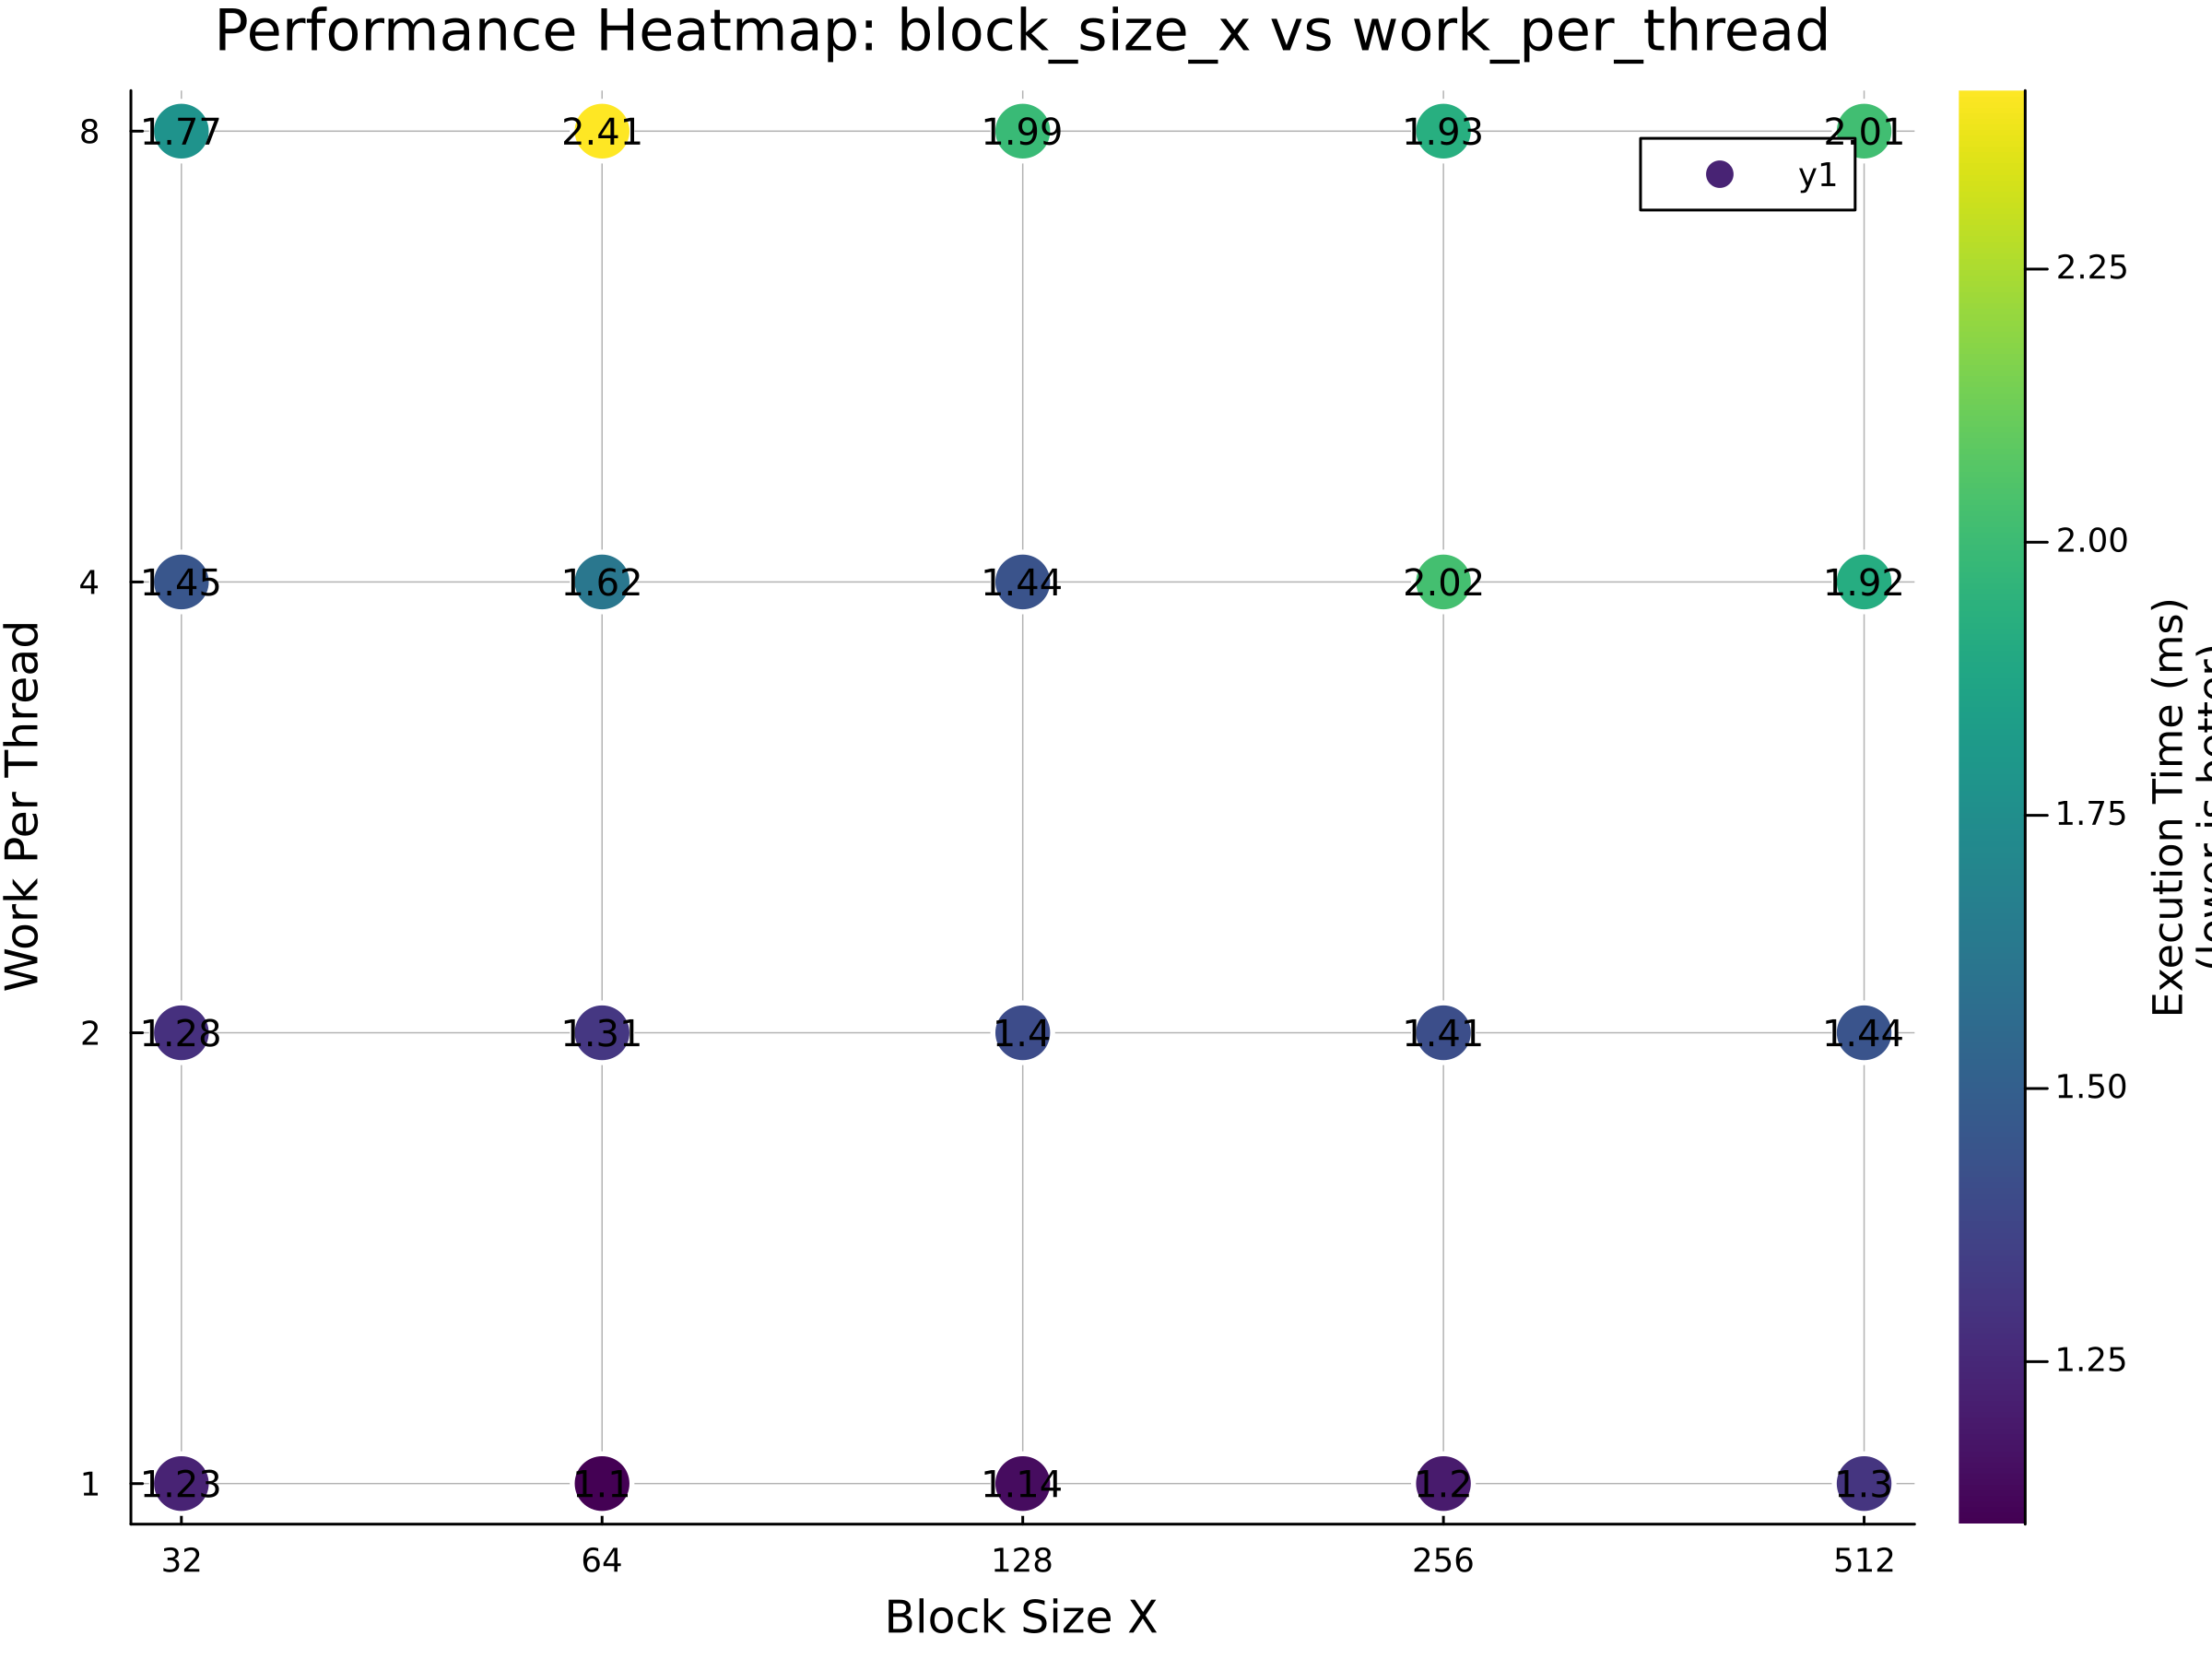

In [7]:
using Plots
using Statistics

# Extract data for plotting
data = results
block_sizes = [d["block_size_x"] for d in data]
work_per_threads = [d["work_per_thread"] for d in data]
performance = [d["time"] for d in data]  # lower is better

# Create the scatter plot
scatter(block_sizes, work_per_threads,
    marker_z = performance,
    markersize = 12,
    markerstrokewidth = 1.5,
    markerstrokecolor = :white,
    color = :viridis,
    colorbar_title = "Execution Time (ms)\n(lower is better)",
    xlabel = "Block Size X",
    ylabel = "Work Per Thread",
    title = "Performance Heatmap: block_size_x vs work_per_thread",
    xscale = :log2,
    yscale = :log2,
    xticks = (sort(unique(block_sizes)), string.(Int.(sort(unique(block_sizes))))),
    yticks = (sort(unique(work_per_threads)), string.(Int.(sort(unique(work_per_threads))))),
    grid = true,
    gridalpha = 0.3,
    size = (800, 600),
    dpi = 300,
    # legend = false,
)

# Annotate each point with its performance value
for (x, y, t) in zip(block_sizes, work_per_threads, performance)
    annotate!(x, y, text(round(t, digits=2), 9, :black, :center))
end

display(current())

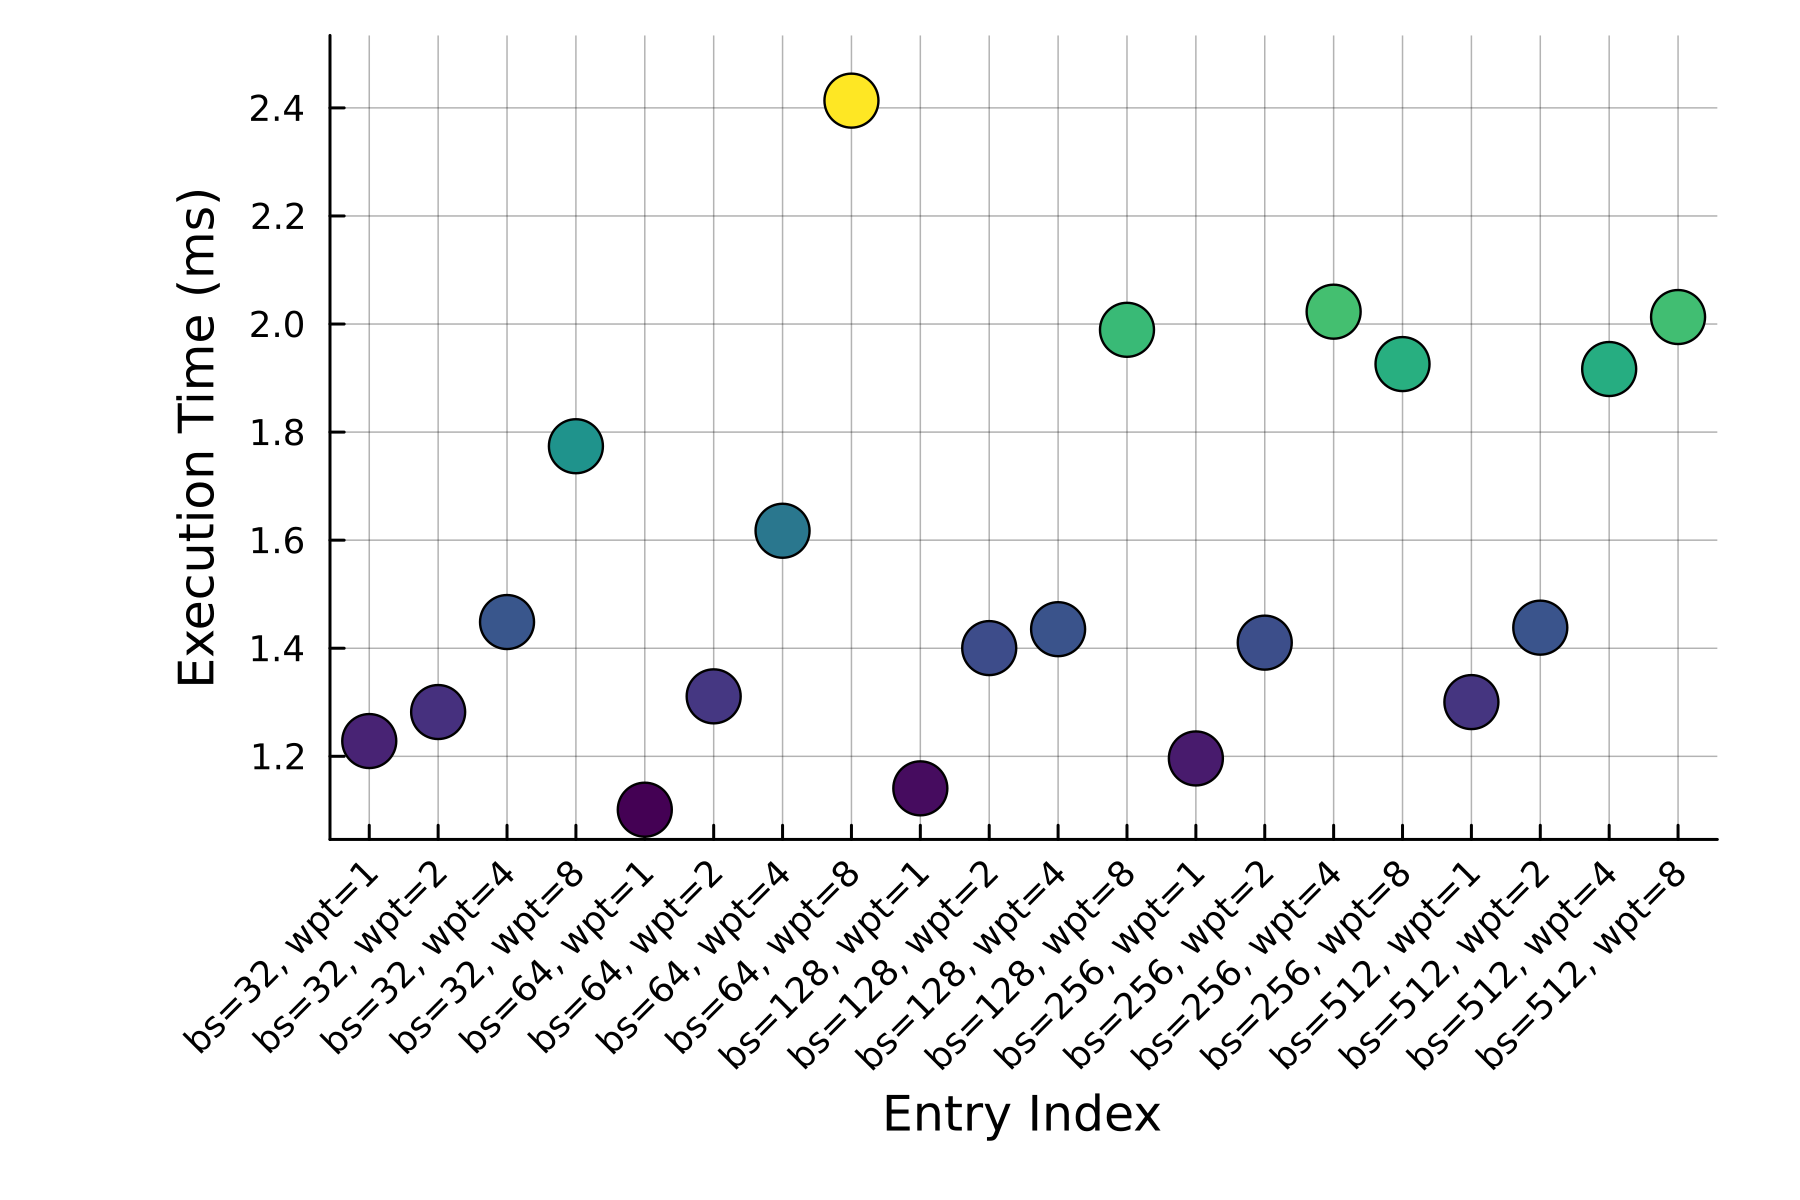

In [8]:
using Plots
using Plots.Measures
using Statistics

# Extract data for plotting
data = results
indices = 1:length(data)
performance = [get(d, "time", NaN) for d in data]  # lower is better
performance_error = [std(d["times"]) for d in data]
block_sizes = [Int(d["block_size_x"]) for d in data]
work_per_threads = [Int(d["work_per_thread"]) for d in data]

# Create labels for each point showing the parameter combination
labels = ["bs=$(bs), wpt=$(wpt)" for (bs, wpt) in zip(block_sizes, work_per_threads)]

# Create the scatter plot
scatter(indices, performance,
    # yerror = performance_error,
    capsize=30,
    marker_z = performance,
    markersize = 10,
    markerstrokewidth = 1,
    # markerstrokecolor = :white,
    color = :viridis,
    colorbar_title = "Execution Time (ms)\n(lower is better)",
    xlabel = "Entry Index",
    ylabel = "Execution Time (ms)",
    # title = "Performance by Entry Index",
    grid = true,
    gridalpha = 0.3,
    # size = (900, 500),
    dpi = 300,
    legend = false,
    xticks = (indices, labels),
    xrotation = 45,
    ylims=(minimum(performance) * 0.95, maximum(performance) * 1.05), 
    bottom_margin = 10mm,
    left_margin = 15mm
)

# # Add a horizontal line at the mean performance
# mean_perf = mean(performance)
# hline!([mean_perf], label = "Mean: $(round(mean_perf, digits=2)) ms", 
#        linestyle = :dash, color = :red, linewidth = 2, alpha = 0.7)

# # Annotate each point with its performance value
# for (i, t) in zip(indices, performance)
#     annotate!(i, t, text(round(t, digits=2), 8, :black, :center, :bottom))
# end

# Save the plot
display(current())

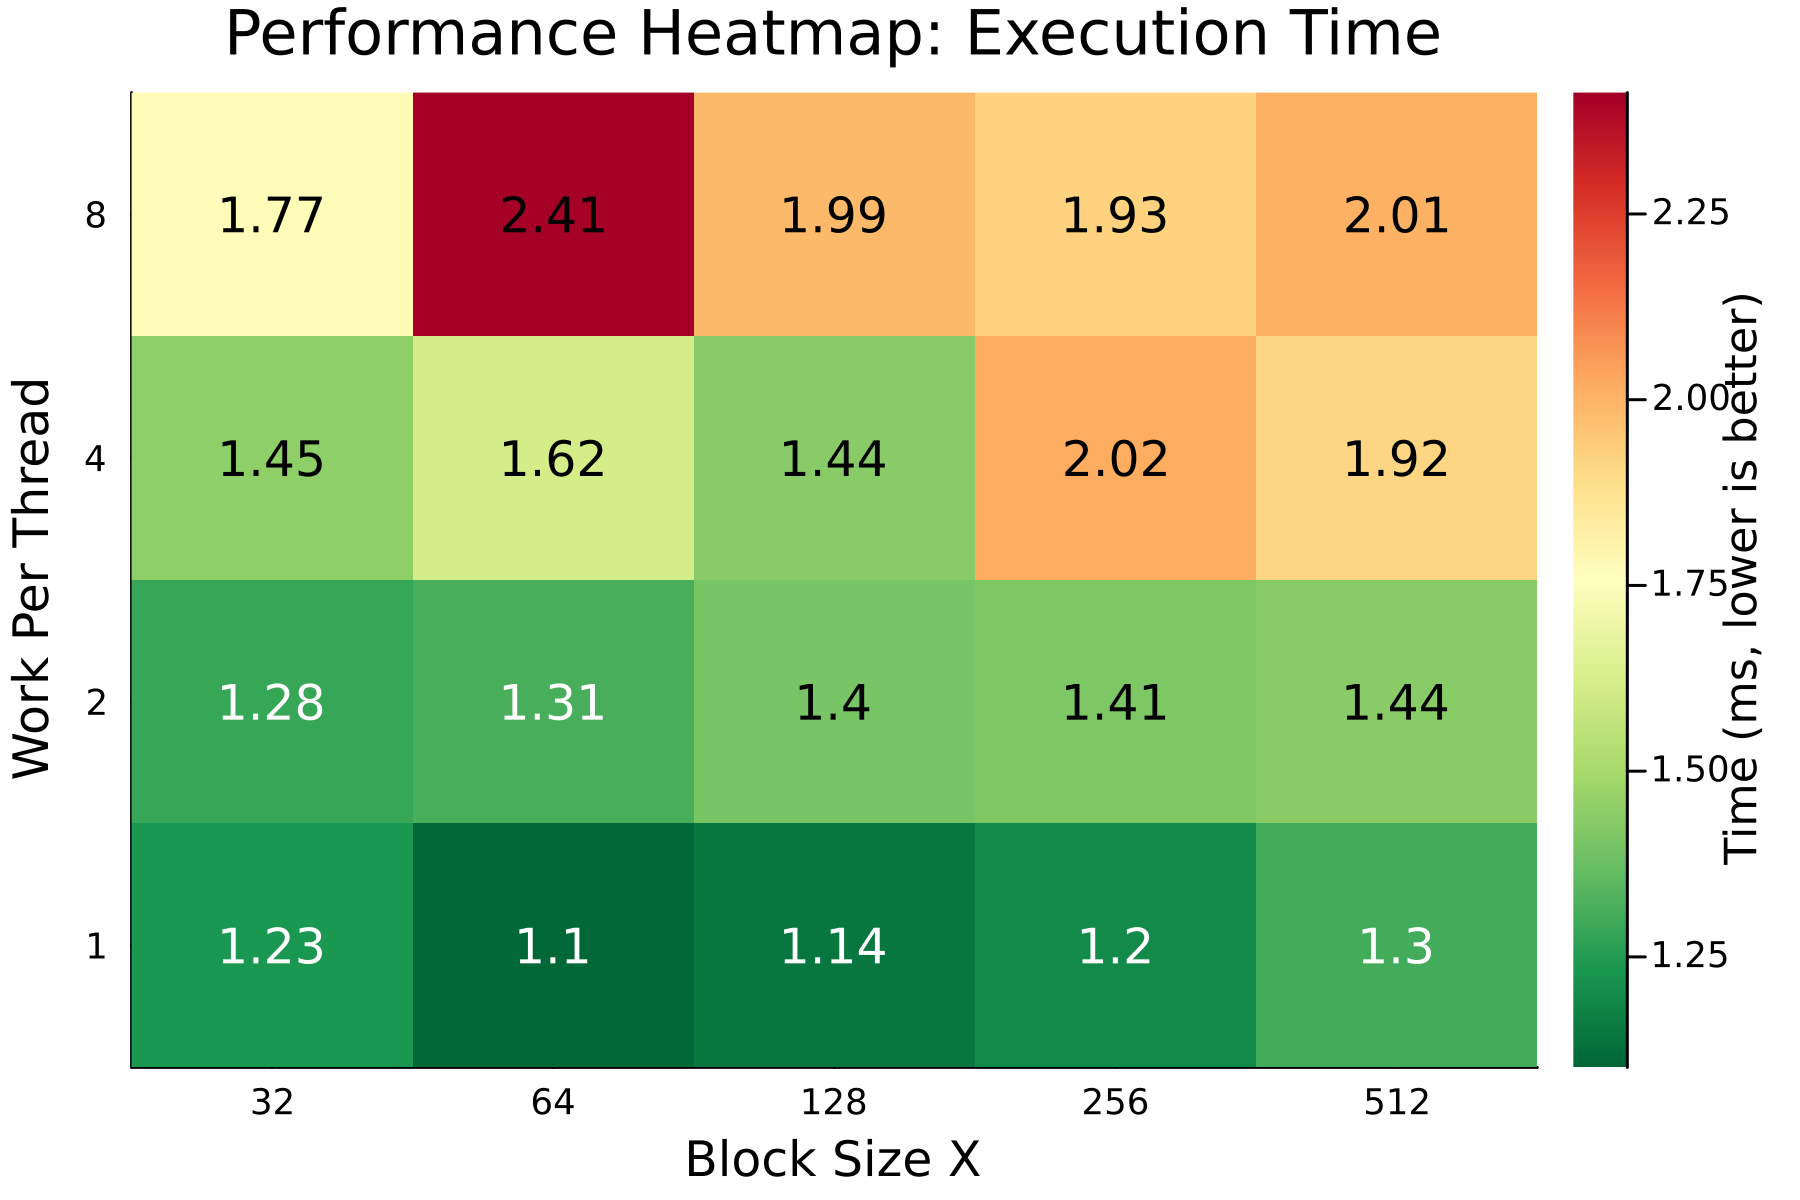

In [9]:
using Plots
using Statistics

# Unique sorted values for axes
data = results
block_sizes = sort(unique([Int(d["block_size_x"]) for d in data]))
work_per_threads = sort(unique([Int(d["work_per_thread"]) for d in data]))

# Create a matrix for the heatmap
# Rows = work_per_thread, Cols = block_size_x
heatmap_data = Matrix{Float64}(undef, length(work_per_threads), length(block_sizes))

for (i, wpt) in enumerate(work_per_threads)
    for (j, bs) in enumerate(block_sizes)
        # Find the entry with this combination
        entry = findfirst(d -> Int(d["block_size_x"]) == bs && Int(d["work_per_thread"]) == wpt, data)
        heatmap_data[i, j] = data[entry]["time"]
    end
end

# Create the heatmap
heatmap(block_sizes, work_per_threads, heatmap_data,
    xlabel = "Block Size X",
    ylabel = "Work Per Thread",
    title = "Performance Heatmap: Execution Time",
    # color = :viridis,
    color = reverse(cgrad(:RdYlGn)),
    colorbar_title = "Time (ms, lower is better)",
    xticks = (block_sizes, string.(block_sizes)),
    yticks = (work_per_threads, string.(work_per_threads)),
    xscale = :log2,
    yscale = :log2,
    # aspect_ratio = 1,
    # size = (700, 600),
    dpi = 300,
    grid = false,
)

# Annotate each cell with the value
for (i, wpt) in enumerate(work_per_threads)
    for (j, bs) in enumerate(block_sizes)
        val = heatmap_data[i, j]
        # Choose text color based on background brightness
        text_color = val < 1.4 ? :white : :black
        annotate!(bs, wpt, text(round(val, digits=2), 11, text_color, :center))
    end
end

display(current())

<div class="alert alert-info">
  <strong>Syntax tip</strong> <br />The <a href="https://docs.julialang.org/en/v1/base/base/#do" class="alert-link"><tt>do</tt>-block syntax</a> allows you to write (possibly long) anonymous functions and automatically pass them as first argument to functions which take another function as first argument. This syntax is often used in conjunction with <a href="https://docs.julialang.org/en/v1/base/collections/#Base.map" class="alert-link"><tt>map</tt></a>, which takes a function as first argument.
</div>